# Problem ID: Category_01_Problem01_Solution — Autonomous Grid Navigation: Battery vs. Distance

### 1. Problem Narrative:
Balance shortest-path navigation to a goal while preserving battery reserves.

### 2. Objectives:
- **State Space ($S$):** 16 states.
- **Action Space ($A$):** 4 actions (0: UP, 1: DOWN, 2: LEFT, 3: RIGHT).

### 3. Student Deliverables:
1. Implement action selection policy in Cell 4.
2. Implement Q-learning update step in Cell 5.

In [2]:
# Cell 2: Standard Imports & Parameters (LOCKED)
import numpy as np
import matplotlib.pyplot as plt
import random

np.random.seed(42)
random.seed(42)

NUM_EPISODES = 200
MAX_STEPS = 50
ALPHA = 0.1
GAMMA = 0.9
EPSILON = 0.2

In [4]:
# Cell 3: Environment Engine (LOCKED)
class MultiObjEnv:
    def __init__(self):
        self.reset()
    def reset(self):
        self.pos = [0, 0]
        self.battery = 100
        return self._get_state()
    def _get_state(self):
        return self.pos[0] * 4 + self.pos[1]
    def step(self, action):
        deltas = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
        dr, dc = deltas.get(action, (0, 0))
        self.pos[0] = min(max(self.pos[0] + dr, 0), 3)
        self.pos[1] = min(max(self.pos[1] + dc, 0), 3)
        self.battery -= 5
        done = (self.pos == [3, 3]) or (self.battery <= 0)
        reward = 10.0 if self.pos == [3, 3] else (-5.0 if self.battery <= 0 else -1.0)
        return self._get_state(), reward, done

In [5]:
# Cell 4: Agent Action Selection (SOLUTION)
class QLearningAgent:
    def __init__(self, num_states, num_actions, alpha=0.1, gamma=0.9, epsilon=0.2):
        self.num_states = num_states
        self.num_actions = num_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.q_table = np.zeros((num_states, num_actions))

    def choose_action(self, state):
        if random.random() < self.epsilon:
            return random.randint(0, self.num_actions - 1)
        return int(np.argmax(self.q_table[state]))

In [8]:
    def update_agent(self, state, action, reward, next_state, done):
        current_q = self.q_table[state, action]
        target = reward if done else reward + self.gamma * np.max(self.q_table[next_state])
        self.q_table[state, action] = current_q + self.alpha * (target - current_q)

    QLearningAgent.update_agent = update_agent

In [9]:
# Cell 6: Driver Simulation (LOCKED)
env = MultiObjEnv()
agent = QLearningAgent(num_states=16, num_actions=4)
rewards_history = []

for ep in range(200):
    state = env.reset()
    total_reward = 0
    done = False
    step_count = 0
    while not done and step_count < 50:
        action = agent.choose_action(state)
        next_state, reward, done = env.step(action)
        agent.update_agent(state, action, reward, next_state, done)
        state = next_state
        total_reward += reward
        step_count += 1
    rewards_history.append(total_reward)

print(f"Completed 200 episodes.")

Completed 200 episodes.


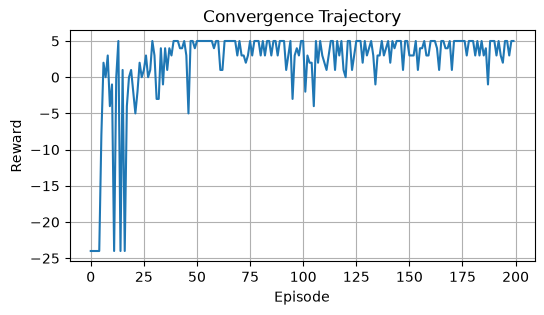

In [10]:
# Cell 7: Visualization (LOCKED)
plt.figure(figsize=(6, 3))
plt.plot(rewards_history)
plt.title('Convergence Trajectory')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.grid(True)
plt.show()